In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
path = kagglehub.dataset_download("annajyang/beehive-sounds")

print("Path to dataset files:", path)

100%|██████████| 19.3G/19.3G [04:17<00:00, 80.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/annajyang/beehive-sounds/versions/3


In [ ]:
# Standard library
import os
from collections import Counter

# Scientific computing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt

# Audio processing
import librosa
import soundfile as sf
from IPython.display import Audio

# TensorFlow and Keras
import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras import metrics

# Scikit-learn utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import minmax_scale
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

# Experiment tracking
import wandb
from wandb.integration.keras import WandbMetricsLogger

# Progress bars
import tqdm

In [ ]:
!ls /root/.cache/kagglehub/datasets/annajyang/beehive-sounds/versions/3

all_data_updated.csv  sound_files


In [ ]:
CONFIG = {
    # W&B
    "project_name": "beehive",
    "run_name": "yamnet-baseline-v2-wandb",

    "seed": 0,

    # Dataset
    "csv_path": "/root/.cache/kagglehub/datasets/annajyang/beehive-sounds/versions/3/all_data_updated.csv",
    "sound_dir": "/root/.cache/kagglehub/datasets/annajyang/beehive-sounds/versions/3/sound_files/sound_files/",
    "n_limit": 2500,          # -1 for full dataset
    "train_frac": 0.70,
    "val_frac": 0.15,
    "test_frac": 0.15,

    # Audio
    "sample_rate": 16000,
    "low_freq": 100,
    "high_freq": 1000,
    "filter_order": 4,

    # Model
    "embedding_size": 1024,
    "hidden_units": 512,

    # Training
    "batch_size": 32,
    "learning_rate": 1e-4,
    "epochs": 1000,
    "patience": 15,
    "eval_threshold": 0.5,
}

assert abs(CONFIG["train_frac"] + CONFIG["val_frac"] + CONFIG["test_frac"] - 1.0) < 1e-9

np.random.seed(CONFIG["seed"])
tf.random.set_seed(CONFIG["seed"])

In [ ]:
from google.colab import userdata

# Fetch W&B API key from Colab Secrets
WANDB_API_KEY = userdata.get("WANDB")

# Login to Weights & Biases
wandb.login(key=WANDB_API_KEY)

# Initialize run
wandb.init(
    project=CONFIG["project_name"],
    name=CONFIG["run_name"],
    config=CONFIG,
)

# Access W&B configuration
config = wandb.config

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: shettyshivam (shivam-shetty) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
def prepare_dataset(df, n_limit):
    """Create a TensorFlow dataset from a DataFrame of (filename, label) pairs."""
    if n_limit != -1:
        df = df.iloc[:n_limit]
    targets = df["queen presence"]
    filenames = df["sound_file_address"]
    ds = tf.data.Dataset.from_tensor_slices((filenames, targets))
    return ds


def bandpass_filter(wav, sr, low, high, order=4):
    """Butterworth band-pass filter isolating the acoustic band of interest."""
    sos = butter(order, [low, high], btype="bandpass", fs=sr, output="sos")
    return sosfilt(sos, wav)


def normalize_amplitude(wav):
    """Min-max normalize a waveform to [-1, 1]."""
    return minmax_scale(wav, feature_range=(-1, 1))


def pad_or_trim(wav, target_len):
    """Pad or trim waveform to a fixed length.

    Fix vs. baseline: `wav[]` was invalid/no-op; trimming now actually
    slices to `target_len`.
    """
    if len(wav) < target_len:
        padding = target_len - len(wav)
        wav = np.pad(wav, (0, padding), mode="constant")
    else:
        wav = wav[:target_len]
    return wav


def preprocess_audio(wav, sr, low, high, order):
    """Bandpass filter + amplitude normalize a waveform."""
    wav = bandpass_filter(wav, sr, low=low, high=high, order=order)
    wav = normalize_amplitude(wav)
    return wav


def load_wav_16k_mono(filename):
    """Load a WAV file, resample to config.sample_rate mono, preprocess."""
    waveform, sr = librosa.load(
        filename.numpy().decode("utf-8"), sr=config.sample_rate, mono=True
    )
    waveform = preprocess_audio(
        waveform, sr, config.low_freq, config.high_freq, config.filter_order
    )
    return tf.convert_to_tensor(waveform, dtype=tf.float32)


def load_wav_wrapper(filename):
    return tf.py_function(load_wav_16k_mono, [filename], tf.float32)


def load_wav_for_map(filename, label):
    return load_wav_wrapper(filename), label


def extract_embedding(wav_data, label):
    """Run YAMNet and mean-pool frame embeddings into a single clip embedding."""
    scores, embeddings, spectrogram = yamnet_model(wav_data)
    clip_embedding = tf.reduce_mean(embeddings, axis=0)  # shape: (1024,)
    return clip_embedding, label


def evaluate_model_on_dataset(model, ds, threshold=0.5, split_name="eval", plot=True):
    """Evaluate a binary classifier on a dataset, print + optionally plot metrics.

    Returns a dict of metrics so callers can log them (e.g. to W&B).
    """
    y_true, y_pred_probs = [], []

    for waveforms, labels in ds:
        preds = model(waveforms, training=False)
        probs = preds.numpy().squeeze()
        lbls = labels.numpy()

        y_true.extend(np.atleast_1d(lbls).tolist())
        y_pred_probs.extend(np.atleast_1d(probs).tolist())

    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred_binary = (y_pred_probs >= threshold).astype(int)

    results = {
        "auroc": roc_auc_score(y_true, y_pred_probs),
        "auprc": average_precision_score(y_true, y_pred_probs),
        "accuracy": accuracy_score(y_true, y_pred_binary),
        "precision": precision_score(y_true, y_pred_binary, zero_division=0),
        "recall": recall_score(y_true, y_pred_binary, zero_division=0),
        "f1": f1_score(y_true, y_pred_binary, zero_division=0),
    }
    cm = confusion_matrix(y_true, y_pred_binary)

    print(f"Evaluation metrics [{split_name}]:")
    for k, v in results.items():
        print(f"  {k}: {v:.4f}")
    print("Confusion Matrix:")
    print(cm)

    if plot:
        fpr, tpr, _ = roc_curve(y_true, y_pred_probs)
        precs, recalls, _ = precision_recall_curve(y_true, y_pred_probs)

        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.plot(fpr, tpr, label=f"AUC = {results['auroc']:.2f}")
        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"ROC Curve ({split_name})")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(recalls, precs, label=f"AUC = {results['auprc']:.2f}")
        plt.xlabel("Recall")
        plt.ylabel("Precision")
        plt.title(f"Precision-Recall Curve ({split_name})")
        plt.legend()

        plt.tight_layout()
        plt.show()

    results["confusion_matrix"] = cm.tolist()
    return results


def run_inference_on_file(file_name, my_model, yamnet_model):
    """End-to-end inference on a single WAV file. Returns P(queen present)."""
    waveform, sr = librosa.load(file_name, sr=config.sample_rate, mono=True)
    waveform = preprocess_audio(
        waveform, sr, config.low_freq, config.high_freq, config.filter_order
    )
    waveform_tensor = tf.convert_to_tensor(waveform, dtype=tf.float32)

    scores, embeddings, spectrogram = yamnet_model(waveform_tensor)
    final_embedding = tf.reduce_mean(embeddings, axis=0)

    classifier_output = my_model(final_embedding[None, :])
    return float(classifier_output.numpy().squeeze())

In [ ]:
train_meta = pd.read_csv(config.csv_path)
df = train_meta[["file name", "queen presence"]].copy()

# Match rows in the CSV to the actual audio files on disk
sound_files = os.listdir(config.sound_dir)
sound_df = pd.DataFrame(sound_files, columns=["sound_file"])
sound_df["extracted file name"] = sound_df["sound_file"].str.extract(
    r"^(.+_\d+)__segment\d+\.\w+$"
)
df["extracted file name"] = df["file name"].str.extract(r"(.+)\.raw")

final_df = pd.merge(df, sound_df, on="extracted file name")
final_df["sound_file_address"] = config.sound_dir + final_df["sound_file"]

# Flip label polarity so the minority class (queen absent) is class 1 --
# makes precision/recall/F1 read naturally from the minority-class POV.
final_df["queen presence"] = (final_df["queen presence"] - 1).abs()
class_names = ["queen present", "queen not present"]

print(final_df["queen presence"].value_counts())

if config.n_limit != -1:
    final_df = final_df.iloc[: config.n_limit].reset_index(drop=True)

wandb.log({
    "num_samples": len(final_df),
    "class0_queen_present": int((final_df["queen presence"] == 0).sum()),
    "class1_queen_absent": int((final_df["queen presence"] == 1).sum()),
})

queen presence
0    6154
1     946
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# 1. Create a single split for Train / Temp (Val + Test)
gss1 = GroupShuffleSplit(n_splits=1, test_size=(CONFIG["val_frac"] + CONFIG["test_frac"]), random_state=CONFIG["seed"])
train_idx, temp_idx = next(gss1.split(final_df, final_df["queen presence"], groups=final_df["extracted file name"]))

train_df = final_df.iloc[train_idx]
temp_df = final_df.iloc[temp_idx]

# 2. Split the Temp set into Val and Test
relative_test_frac = CONFIG["test_frac"] / (CONFIG["val_frac"] + CONFIG["test_frac"])
gss2 = GroupShuffleSplit(n_splits=1, test_size=relative_test_frac, random_state=CONFIG["seed"])
val_idx, test_idx = next(gss2.split(temp_df, temp_df["queen presence"], groups=temp_df["extracted file name"]))

val_df = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

print(f"train: {len(train_df)}  val: {len(val_df)}  test: {len(test_df)}")
print("train class balance:\n", train_df["queen presence"].value_counts(normalize=True))
print("val class balance:\n", val_df["queen presence"].value_counts(normalize=True))
print("test class balance:\n", test_df["queen presence"].value_counts(normalize=True))

wandb.log({
    "train_size": len(train_df),
    "val_size": len(val_df),
    "test_size": len(test_df),
})

train: 1747  val: 377  test: 376
train class balance:
 queen presence
0    0.72925
1    0.27075
Name: proportion, dtype: float64
val class balance:
 queen presence
0    0.748011
1    0.251989
Name: proportion, dtype: float64
test class balance:
 queen presence
0    0.840426
1    0.159574
Name: proportion, dtype: float64


In [ ]:
yamnet_model = hub.load("https://tfhub.dev/google/yamnet/1")

def make_embedding_ds(df, shuffle):
    ds = prepare_dataset(df, n_limit=-1)  # already limited/split at dataframe level
    ds = ds.map(load_wav_for_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(extract_embedding, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=max(len(df), 1), seed=config.seed)
    ds = ds.batch(config.batch_size).cache().prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_embedding_ds(train_df, shuffle=True)
val_ds = make_embedding_ds(val_df, shuffle=False)
test_ds = make_embedding_ds(test_df, shuffle=False)

for example in train_ds.take(1):
    print(example)

(<tf.Tensor: shape=(32, 1024), dtype=float32, numpy=
array([[0.0000000e+00, 8.4601371e-03, 2.9211253e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 3.7138388e-02, 4.8304377e-03, ..., 2.5685257e-04,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 9.9617831e-02, 0.0000000e+00, ..., 2.2938924e-03,
        4.3558818e-03, 0.0000000e+00],
       ...,
       [0.0000000e+00, 4.3637481e-02, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 8.8389926e-02, 6.7011523e-03, ..., 7.7309324e-03,
        2.2092011e-02, 0.0000000e+00],
       [2.0674657e-04, 1.2280225e-02, 3.6391438e-04, ..., 4.8787526e-05,
        0.0000000e+00, 0.0000000e+00]], dtype=float32)>, <tf.Tensor: shape=(32,), dtype=int64, numpy=
array([0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 1, 0])>)


In [ ]:
my_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(config.embedding_size,), dtype=tf.float32, name="input_embedding"),

    tf.keras.layers.Dense(config.hidden_units, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),  # Prevents overfitting

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(1, activation="sigmoid")
], name="enhanced_bee_model")
my_model.compile(
    optimizer=tf.keras.optimizers.Adam(config.learning_rate),
    loss="binary_crossentropy",
    metrics=["accuracy",
        metrics.AUC(name="auroc", curve="ROC"),
        metrics.AUC(name="auprc", curve="PR"),
        metrics.Precision(name="precision"),
        metrics.Recall(name="recall"),
    ],
)

my_model.summary()

Model: "enhanced_bee_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 659,457 (2.52 MB)

 Trainable params: 657,921 (2.51 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [ ]:
classes = [0, 1]
weights = compute_class_weight(
    class_weight="balanced", classes=np.array(classes), y=train_df["queen presence"]
)
class_weight = {0: weights[0], 1: weights[1]}
print("class weights:", class_weight)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=config.patience,
    restore_best_weights=True,
)

history = my_model.fit(
    train_ds,
    validation_data=val_ds,
    class_weight=class_weight,
    epochs=config.epochs,
    callbacks=[
        early_stop,
        WandbMetricsLogger(log_freq="epoch"),
    ],
)

class weights: {0: np.float64(0.6856357927786499), 1: np.float64(1.846723044397463)}
Epoch 1/1000
55/55 ━━━━━━━━━━━━━━━━━━━━ 961s 3s/step - accuracy: 0.5621 - auprc: 0.3580 - auroc: 0.6021 - loss: 0.8311 - precision: 0.3286 - recall: 0.5920 - val_accuracy: 0.2520 - val_auprc: 0.3620 - val_auroc: 0.5857 - val_loss: 0.8087 - val_precision: 0.2520 - val_recall: 1.0000
Epoch 2/1000
55/55 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - accuracy: 0.6090 - auprc: 0.4302 - auroc: 0.6717 - loss: 0.7470 - precision: 0.3753 - recall: 0.6681 - val_accuracy: 0.2520 - val_auprc: 0.3760 - val_auroc: 0.6018 - val_loss: 0.9343 - val_precision: 0.2520 - val_recall: 1.0000
Epoch 3/1000
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6262 - auprc: 0.4879 - auroc: 0.7225 - loss: 0.6716 - precision: 0.3946 - recall: 0.7125 - val_accuracy: 0.2520 - val_auprc: 0.3908 - val_auroc: 0.6501 - val_loss: 1.0198 - val_precision: 0.2520 - val_recall: 1.0000
Epoch 4/1000
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6

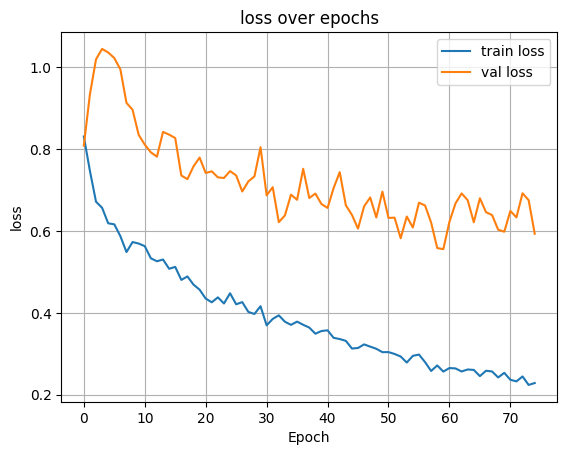

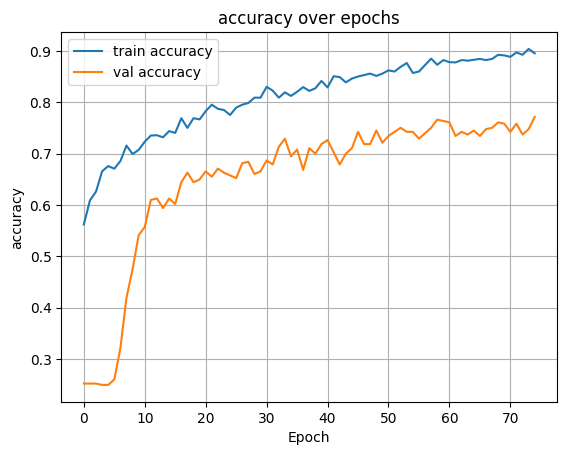

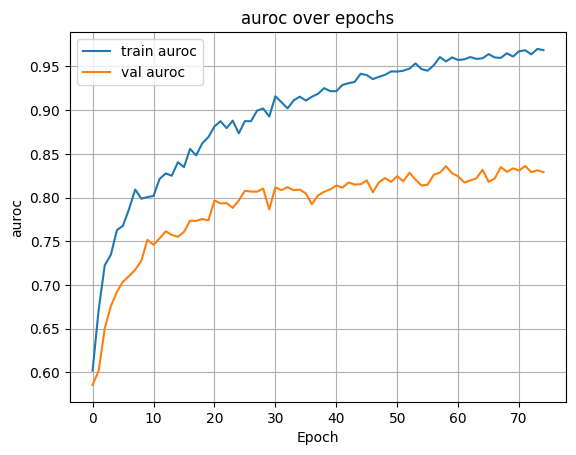

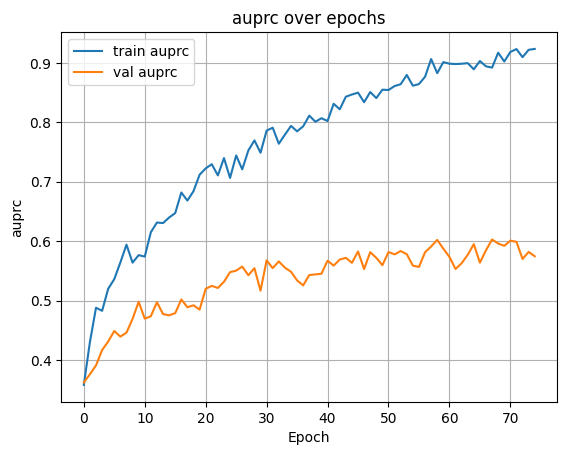

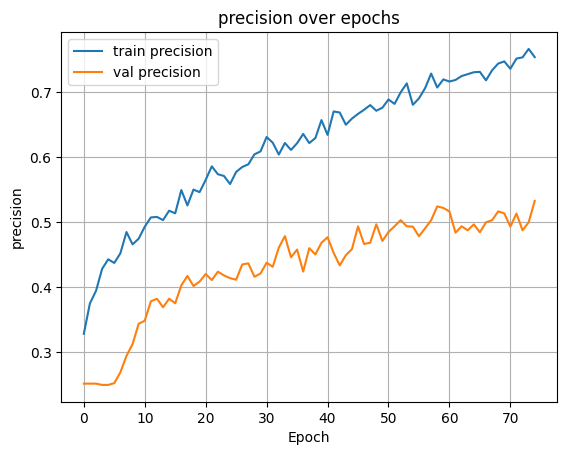

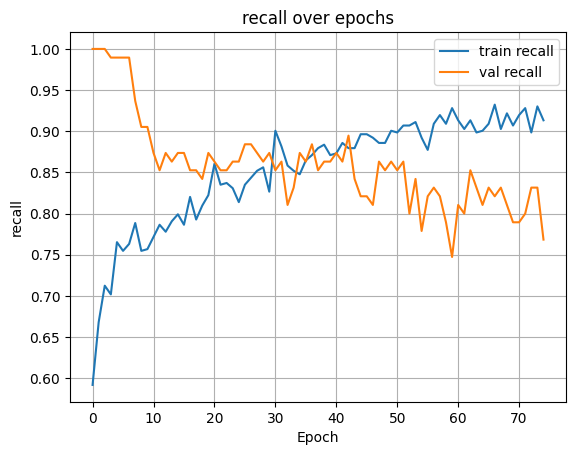

In [ ]:
metric_names = ["loss", "accuracy", "auroc", "auprc", "precision", "recall"]

def plot_history(history, metrics_to_plot):
    for metric in metrics_to_plot:
        plt.figure()
        plt.plot(history.history[metric], label=f"train {metric}")
        plt.plot(history.history[f"val_{metric}"], label=f"val {metric}")
        plt.xlabel("Epoch")
        plt.ylabel(metric)
        plt.title(f"{metric} over epochs")
        plt.legend()
        plt.grid(True)
        plt.show()

plot_history(history, metric_names)

Evaluation metrics [train]:
  auroc: 0.9874
  auprc: 0.9625
  accuracy: 0.9256
  precision: 0.7952
  recall: 0.9767
  f1: 0.8767
Confusion Matrix:
[[1155  119]
 [  11  462]]


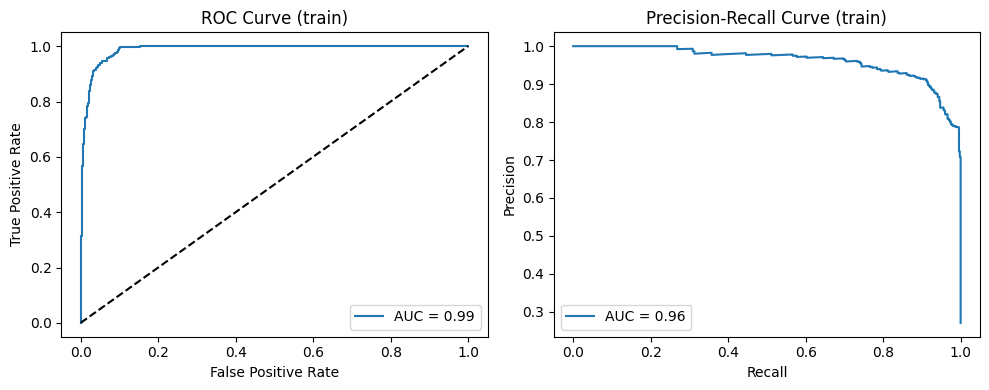

Evaluation metrics [val]:
  auroc: 0.8282
  auprc: 0.5985
  accuracy: 0.7639
  precision: 0.5221
  recall: 0.7474
  f1: 0.6147
Confusion Matrix:
[[217  65]
 [ 24  71]]


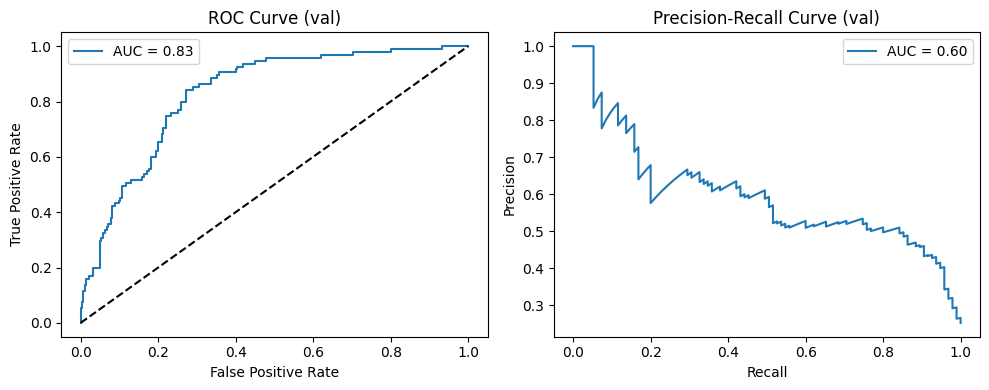

Evaluation metrics [test]:
  auroc: 0.7875
  auprc: 0.3708
  accuracy: 0.7553
  precision: 0.3571
  recall: 0.6667
  f1: 0.4651
Confusion Matrix:
[[244  72]
 [ 20  40]]


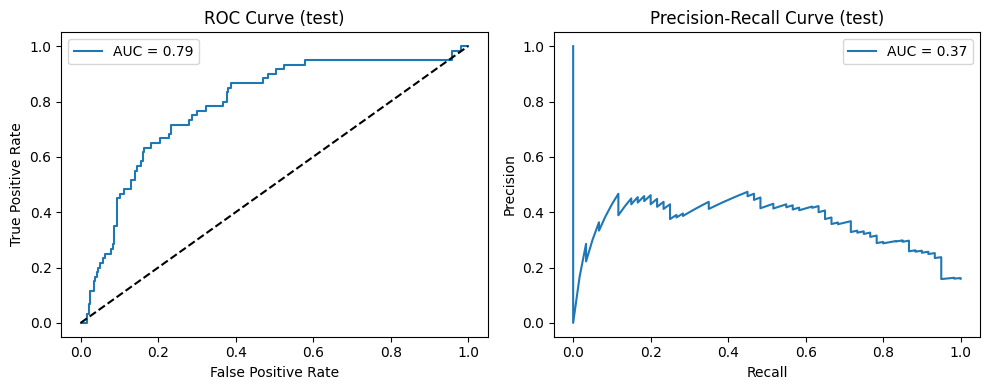

In [ ]:
train_results = evaluate_model_on_dataset(my_model, train_ds, threshold=config.eval_threshold, split_name="train")
val_results = evaluate_model_on_dataset(my_model, val_ds, threshold=config.eval_threshold, split_name="val")
test_results = evaluate_model_on_dataset(my_model, test_ds, threshold=config.eval_threshold, split_name="test")

wandb.log({f"final_train_{k}": v for k, v in train_results.items() if k != "confusion_matrix"})
wandb.log({f"final_val_{k}": v for k, v in val_results.items() if k != "confusion_matrix"})
wandb.log({f"test_{k}": v for k, v in test_results.items() if k != "confusion_matrix"})

In [ ]:
model_path = "/content/yamnet_bee_classifier.keras"
my_model.save(model_path)

artifact = wandb.Artifact("yamnet-queen-classifier", type="model", metadata=dict(config))
artifact.add_file(model_path)
wandb.log_artifact(artifact)

<Artifact yamnet-queen-classifier>

In [ ]:
example_file = test_df["sound_file_address"].iloc[0]
prob_queen_present = run_inference_on_file(example_file, my_model, yamnet_model)
print(f"{example_file} -> P(queen present) = {prob_queen_present:.4f}")

/root/.cache/kagglehub/datasets/annajyang/beehive-sounds/versions/3/sound_files/sound_files/2022-06-08--15-51-41_1__segment4.wav -> P(queen present) = 0.2382


In [ ]:
import tensorflow as tf
import numpy as np

# 1. Load your saved Keras classification model
keras_model_path = model_path
model = tf.keras.models.load_model(keras_model_path)

# 2. Define a representative dataset generator using your train dataset
# We need to yield a list of matching input tensors
def representative_data_gen():
    # Take a small batch subset from your train_ds (e.g., ~100-200 samples)
    # train_ds yields (embeddings, labels), we only need the embeddings
    for embeddings, _ in train_ds.take(5):
        for embedding in embeddings:
            # Expand dimensions to match the model input shape: (1, 1024)
            yield [np.array(embedding, dtype=np.float32)[np.newaxis, :]]

# 3. Set up the TFLite Converter
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 4. Enforce Full Integer Quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen

# Ensure that all operations are fully converted to 8-bit integers
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

# Set the input and output tensors to int8 (crucial for microcontrollers)
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# 5. Convert the model
tflite_quant_model = converter.convert()

# 6. Save the quantized TFLite model
quant_model_path = "/content/yamnet_bee_classifier_quant.tflite"
with open(quant_model_path, "wb") as f:
    f.write(tflite_quant_model)

print(f"Quantized TFLite model successfully saved to: {quant_model_path}")

Saved artifact at '/tmp/tmpui7r49bp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1024), dtype=tf.float32, name='input_embedding')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133080768045200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768044240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768047120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768037328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768039632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768044816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768047696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768046160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768048080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768047888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133080768036944: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Quantized TFLite model successfully saved to: /content/yamnet_bee_classifier_quant.tflite


In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)
interpreter = tf.lite.Interpreter(model_path='/content/yamnet_bee_classifier_quant.tflite')
interpreter.allocate_tensors()

# 2. Get input and output tensor details (including quantization parameters)
input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_index = input_details["index"]
output_index = output_details["index"]

# Extract scale and zero point for quantization/dequantization mapping
input_scale, input_zero_point = input_details["quantization"]
output_scale, output_zero_point = output_details["quantization"]

y_true = []
y_pred_probs = []

print("Running inference with quantized TFLite Interpreter...")

# 3. Iterate through your evaluation/test dataset
# (Note: test_ds yields float32 embeddings of shape (batch_size, 1024))
for embeddings, labels in test_ds:
    labels_np = labels.numpy()
    embeddings_np = embeddings.numpy()

    for i in range(len(labels_np)):
        single_embedding = embeddings_np[i][np.newaxis, :] # Shape: (1, 1024)

        # Quantize input: Convert float32 embedding -> int8
        # Formula: int8_val = round(float_val / scale) + zero_point
        quant_input = np.round(single_embedding / input_scale) + input_zero_point
        quant_input = np.clip(quant_input, -128, 127).astype(np.int8)

        # Set the tensor and invoke interpreter
        interpreter.set_tensor(input_index, quant_input)
        interpreter.invoke()

        # Get quantized output tensor (int8)
        quant_output = interpreter.get_tensor(output_index)

        # Dequantize output: Convert int8 -> float32 probability
        # Formula: float_val = (int8_val - zero_point) * scale
        prob = (quant_output.astype(np.float32) - output_zero_point) * output_scale
        prob = np.squeeze(prob)

        y_true.append(labels_np[i])
        y_pred_probs.append(prob)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)

# 4. Apply your optimal threshold (e.g., 0.35 from your previous optimal run)
eval_threshold = 0.35
y_pred_binary = (y_pred_probs >= eval_threshold).astype(int)

# 5. Compute and Print Quantized Metrics
tflite_results = {
    "auroc": roc_auc_score(y_true, y_pred_probs),
    "auprc": average_precision_score(y_true, y_pred_probs),
    "accuracy": accuracy_score(y_true, y_pred_binary),
    "precision": precision_score(y_true, y_pred_binary, zero_division=0),
    "recall": recall_score(y_true, y_pred_binary, zero_division=0),
    "f1": f1_score(y_true, y_pred_binary, zero_division=0),
}
cm = confusion_matrix(y_true, y_pred_binary)

print("\n=== Quantized TFLite Model Evaluation Metrics ===")
for k, v in tflite_results.items():
    print(f"  Quantized {k.upper()}: {v:.4f}")
print("\nQuantized Confusion Matrix:")
print(cm)

Running inference with quantized TFLite Interpreter...

=== Quantized TFLite Model Evaluation Metrics ===
  Quantized AUROC: 0.7873
  Quantized AUPRC: 0.3742
  Quantized ACCURACY: 0.7207
  Quantized PRECISION: 0.3358
  Quantized RECALL: 0.7667
  Quantized F1: 0.4670

Quantized Confusion Matrix:
[[225  91]
 [ 14  46]]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
